# Fase 2 — Desarrollo, Modelado y Evaluación
## MATERNA · Sistema de alerta temprana de riesgo materno-perinatal (La Guajira y Cesar)
**Proyecto de aula — Inteligencia Artificial · Universidad Popular del Cesar**

Este notebook ejecuta y documenta el pipeline del repositorio (`src/`). Toda la lógica vive en módulos versionados. El notebook solo los orquesta y muestra los resultados, para que lo que se presenta sea exactamente lo que está en el código.

| Sub-fase | Módulo | Contenido |
|---|---|---|
| 2.1 Preprocesamiento | `src/data_preprocessing.py` | Limpieza, imputación estratificada sin fuga, RobustScaler, One-Hot, partición 70/15/15 |
| 2.2 Modelado | `src/train_models.py` | Regresión Logística (baseline) y SVM, GridSearchCV con 5-fold estratificado, SMOTE vs. class_weight |
| 2.3 Reglas clínicas | `src/clinical_rules.py` | Motor híbrido `evaluar_riesgo_hibrido()` |
| 2.4 Evaluación | `src/evaluate.py` | Métricas en prueba, IC 95 % bootstrap, matrices de confusión, ROC, costo clínico, auditoría de sesgos |

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 2.1 Preprocesamiento

In [2]:
from src.data_preprocessing import cargar_dataset, reporte_calidad, preparar_datos, construir_preprocesador

for clave, valor in reporte_calidad(cargar_dataset()).items():
    print(f"{clave}: {valor}")

X_train, X_val, X_test, y_train, y_val, y_test = preparar_datos()
pd.DataFrame({n: y.value_counts().sort_index() for n, y in [("train", y_train), ("val", y_val), ("test", y_test)]}
             ).rename(index={0: "Bajo", 1: "Medio", 2: "Alto"}).T.assign(total=lambda d: d.sum(axis=1))

registros: 1200
columnas: 16
ids_duplicados: 0
filas_duplicadas_sin_id: 0
nulos: {'fcf_bpm': 89, 'glucosa_mgdl': 159}
pct_nulos: {'fcf_bpm': 7.42, 'glucosa_mgdl': 13.25}
fuera_de_rango_fisiologico: {}
distribucion_target: {'Bajo Riesgo': 578, 'Riesgo Medio': 470, 'Alto Riesgo': 152}


riesgo_obstetrico,Bajo,Medio,Alto,total
train,405,329,106,840
val,86,71,23,180
test,87,70,23,180


**Decisiones de preprocesamiento**
- **Imputación** de `glucosa_mgdl` y `fcf_bpm` con la mediana del estrato *área de residencia × trimestre*, como se definió en el documento de la Fase 1. Si el estrato tiene menos de 10 observaciones, se usa la mediana por área y, si no alcanza, la global. Las medianas se aprenden **solo con entrenamiento**, porque el imputador es un paso del Pipeline.
- **Indicadores** `glucosa_no_disponible` y `fcf_no_disponible`: en campo, la falta de glucómetro o doppler fetal es información sobre el acceso.
- **RobustScaler** sobre las 7 variables continuas, para que las crisis hipertensivas reales no distorsionen la escala.
- **One-Hot** solo en las variables de acceso (`area_residencia`, `atendido_por`). Departamento, municipio y etnia **no** entran al modelo: no mejoran el desempeño (ver ablación) y su inclusión podría convertir la identidad étnica en un *proxy* de riesgo.
- **Target ordinal:** Bajo → 0, Medio → 1, Alto → 2.

In [3]:
pre = construir_preprocesador().fit(X_train)
Xt = pd.DataFrame(pre.transform(X_train), columns=pre.get_feature_names_out())
print("Matriz de entrenamiento transformada:", Xt.shape)
imp = pre.named_steps["imputacion"]
print("\nMedianas de imputación aprendidas (estrato -> valor):")
for col in imp.columnas:
    print(" ", col, {f"{a}/{t}": round(v, 1) for (a, t), v in imp.mediana_estrato_[col].items()})
Xt.head()

Matriz de entrenamiento transformada: (840, 17)

Medianas de imputación aprendidas (estrato -> valor):
  glucosa_mgdl {'Cabecera/T2': 102.4, 'Cabecera/T3': 96.3, 'Rural disperso/T1': 101.3, 'Rural disperso/T2': 97.2, 'Rural disperso/T3': 99.6}
  fcf_bpm {'Cabecera/T2': 139.8, 'Cabecera/T3': 139.8, 'Rural disperso/T1': 146.2, 'Rural disperso/T2': 140.5, 'Rural disperso/T3': 139.0}


,edad,semanas_gestacion,n_controles_prenatales,pas_mmhg,pad_mmhg,fcf_bpm,glucosa_mgdl,proteinuria,convulsiones,glucosa_no_disponible,fcf_no_disponible,area_residencia_Cabecera,area_residencia_Rural disperso,atendido_por_Auxiliar de enfermeria,atendido_por_Enfermero(a),atendido_por_Medico,atendido_por_Partera tradicional
0,0.666667,-0.444444,0.25,-0.176471,0.000000,0.499248,0.099187,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.444444,0.444444,0.00,-0.235294,1.636364,0.324812,2.414634,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.111111,0.888889,0.25,-1.058824,-0.363636,1.275188,3.182114,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.000000,0.222222,0.25,-0.352941,-0.727273,0.896241,-1.279675,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,-1.222222,0.000000,0.00,-0.823529,0.090909,0.000000,0.066667,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0


## 2.2 Experimentación y entrenamiento
- **Baseline:** Regresión Logística multinomial (lbfgs), con C en 13 valores de 10⁻³ a 10³.
- **Modelo avanzado:** SVM con kernels `rbf`, `linear` y `poly`; C ∈ {0.1, 1, 10, 100}; γ ∈ {scale, 0.01, 0.1, 1}; grado ∈ {2, 3}.
- **Balanceo como hiperparámetro:** (a) SMOTE dentro de cada fold o (b) `class_weight='balanced'`. No se combinan, para no compensar el desbalance dos veces.
- **Validación cruzada:** 5-fold estratificada sobre entrenamiento. La configuración se elige por **F1-macro** y se registra también el recall de Alto Riesgo.
- **Probabilidades del SVM:** `SVC(probability=True)` está deprecado en scikit-learn 1.9, así que se calibra con `CalibratedClassifierCV` (sigmoide, 5 folds).

La celda siguiente ejecuta la búsqueda completa: 130 configuraciones × 5 folds, en aproximadamente un minuto.

In [4]:
from src.train_models import entrenar_todo
modelos = entrenar_todo()

[Regresión Logística] 26 configuraciones x 5 folds en 19.6 s
[Regresión Logística] mejor f1_macro CV = 0.7499 | {'balanceo': 'class_weight', 'C': np.float64(10.0)}


[SVM] 104 configuraciones x 5 folds en 28.6 s
[SVM] mejor f1_macro CV = 0.8608 | {'balanceo': 'class_weight', 'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}

Comparación en validación cruzada (mejor configuración por modelo y estrategia):
             modelo     balanceo                                 hiperparametros  cv_f1_macro_media  cv_f1_macro_std  cv_f1_weighted_media  cv_f1_weighted_std  cv_balanced_accuracy_media  cv_balanced_accuracy_std  cv_accuracy_media  cv_accuracy_std  cv_recall_alto_media  cv_recall_alto_std  cv_precision_alto_media  cv_precision_alto_std  cv_f1_alto_media  cv_f1_alto_std  tiempo_ajuste_s
                SVM class_weight {'C': 100.0, 'gamma': 'scale', 'kernel': 'rbf'}             0.8608           0.0110                0.8668              0.0132                      0.8569                    0.0154             0.8667           0.0139                0.8316              0.0771                   0.8871                 0.0973            0.8509          0.0391 


Ablación de variables demográficas:
              modelo                        variables  cv_f1_macro_media  cv_recall_alto_media  cv_balanced_accuracy_media
Regresión Logística  clínicas + acceso (por defecto)             0.7499                0.9065                      0.7633
Regresión Logística clínicas + acceso + demográficas             0.7273                0.8597                      0.7401
                SVM  clínicas + acceso (por defecto)             0.8608                0.8316                      0.8569
                SVM clínicas + acceso + demográficas             0.8279                0.7662                      0.8215


In [5]:
from src.config import DIR_METRICAS
comparacion = pd.read_csv(DIR_METRICAS / "comparacion_cv_por_estrategia.csv")
cols = ["modelo", "balanceo", "hiperparametros", "cv_f1_macro_media", "cv_f1_macro_std", "cv_balanced_accuracy_media",
        "cv_recall_alto_media", "cv_recall_alto_std", "cv_precision_alto_media", "tiempo_ajuste_s"]
comparacion[cols]

,modelo,balanceo,hiperparametros,cv_f1_macro_media,cv_f1_macro_std,cv_balanced_accuracy_media,cv_recall_alto_media,cv_recall_alto_std,cv_precision_alto_media,tiempo_ajuste_s
0,SVM,class_weight,"{'C': 100.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.8608,0.0110,0.8569,0.8316,0.0771,0.8871,0.1649
1,SVM,SMOTE,"{'C': 10.0, 'gamma': 0.1, 'kernel': 'rbf'}",0.8454,0.0296,0.8460,0.8411,0.0825,0.8525,0.1905
2,Regresión Logística,class_weight,{'C': 10.0},0.7499,0.0129,0.7633,0.9065,0.0649,0.8134,0.1748
3,Regresión Logística,SMOTE,{'C': 0.3162},0.7467,0.0330,0.7582,0.8965,0.0343,0.8166,0.2053


In [6]:
exp = pd.read_csv(DIR_METRICAS / "experimentos_cv_completo.csv")
print(f"Registro completo: {len(exp)} configuraciones evaluadas")
exp[exp["modelo"] == "SVM"].groupby(["kernel", "balanceo"])[["cv_f1_macro_media", "cv_recall_alto_media", "tiempo_ajuste_s"]].max().round(4)

Registro completo: 130 configuraciones evaluadas


cv_f1_macro_media  cv_recall_alto_media  tiempo_ajuste_s
kernel balanceo                                                              
linear SMOTE                    0.7542                0.8874           1.6204
       class_weight             0.7527                0.8874           1.1851
poly   SMOTE                    0.8401                0.8407           4.1975
       class_weight             0.8374                0.8502           2.6253
rbf    SMOTE                    0.8454                0.8788           0.3595
       class_weight             0.8608                0.8874           0.2400

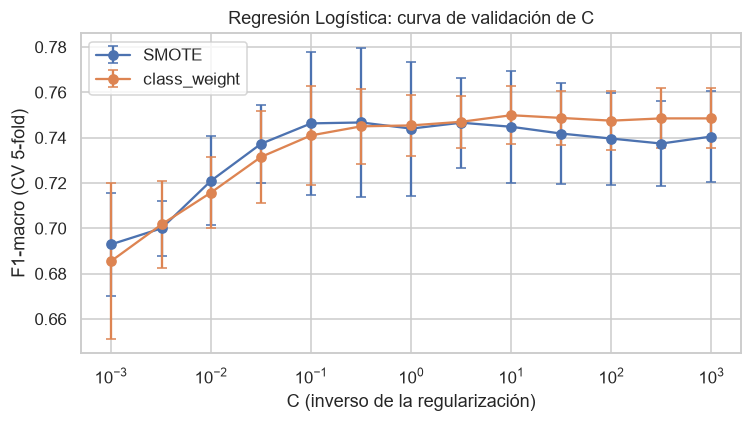

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
lr = exp[exp["modelo"] == "Regresión Logística"]
for estrategia, grupo in lr.groupby("balanceo"):
    grupo = grupo.sort_values("C")
    ax.errorbar(grupo["C"], grupo["cv_f1_macro_media"], yerr=grupo["cv_f1_macro_std"], marker="o", capsize=3, label=estrategia)
ax.set_xscale("log"); ax.set_xlabel("C (inverso de la regularización)"); ax.set_ylabel("F1-macro (CV 5-fold)")
ax.set_title("Regresión Logística: curva de validación de C"); ax.legend()
plt.tight_layout(); plt.show()

In [8]:
pd.read_csv(DIR_METRICAS / "ablacion_variables_demograficas.csv")

,modelo,variables,cv_f1_macro_media,cv_recall_alto_media,cv_balanced_accuracy_media
0,Regresión Logística,clínicas + acceso (por defecto),0.7499,0.9065,0.7633
1,Regresión Logística,clínicas + acceso + demográficas,0.7273,0.8597,0.7401
2,SVM,clínicas + acceso (por defecto),0.8608,0.8316,0.8569
3,SVM,clínicas + acceso + demográficas,0.8279,0.7662,0.8215


**Lectura de la experimentación**
- El SVM RBF supera claramente a la Regresión Logística en F1-macro (≈0,86 frente a ≈0,75). Las etiquetas dependen de umbrales, que no son lineales, y la frontera lineal confunde Bajo con Medio.
- La Regresión Logística tiene **mayor recall en Alto Riesgo** en CV, a costa de una precisión menor: alerta más, pero con más falsos positivos.
- `class_weight` y SMOTE rinden de forma parecida. `class_weight` gana por poco y es más simple, así que es la estrategia final.
- El mejor C del SVM (100) está en el **borde de la grilla** pedida. Ampliarla (C = 300 o 1000) queda como trabajo para la Fase 3.
- Agregar las variables demográficas **empeora** ambos modelos, lo que confirma la decisión de excluirlas.

## 2.3 Motor híbrido de reglas clínicas

In [9]:
from src.clinical_rules import evaluar_riesgo_hibrido, UMBRAL_PAS_SEVERA, UMBRAL_PAD_SEVERA, UMBRAL_PROTEINURIA
print(f"Reglas: PAS >= {UMBRAL_PAS_SEVERA} | PAD >= {UMBRAL_PAD_SEVERA} | convulsiones | proteinuria >= {UMBRAL_PROTEINURIA} (++)")

casos = {
    "Emergencia (Uribia, sin doppler)": dict(edad=26, departamento="La Guajira", municipio="Uribia", pertenencia_etnica="Wayuu",
        area_residencia="Rural disperso", semanas_gestacion=31, n_controles_prenatales=1, atendido_por="Partera tradicional",
        pas_mmhg=165, pad_mmhg=108, fcf_bpm=None, glucosa_mgdl=110.5, proteinuria=2, convulsiones=1),
    "Adolescente sin controles (Manaure)": dict(edad=17, departamento="La Guajira", municipio="Manaure", pertenencia_etnica="Wayuu",
        area_residencia="Rural disperso", semanas_gestacion=24, n_controles_prenatales=0, atendido_por="Auxiliar de enfermeria",
        pas_mmhg=128, pad_mmhg=82, fcf_bpm=150.0, glucosa_mgdl=None, proteinuria=0, convulsiones=0),
    "Control de rutina (Valledupar)": dict(edad=27, departamento="Cesar", municipio="Valledupar", pertenencia_etnica="Mestiza",
        area_residencia="Cabecera", semanas_gestacion=28, n_controles_prenatales=5, atendido_por="Medico",
        pas_mmhg=110, pad_mmhg=70, fcf_bpm=142.0, glucosa_mgdl=88.0, proteinuria=0, convulsiones=0),
}
filas = []
for nombre, registro in casos.items():
    r = evaluar_riesgo_hibrido(registro, modelos["SVM"])
    filas.append({"caso": nombre, "categoría final": r.categoria, "origen": r.origen, "predicción SVM": r.categoria_modelo,
                  **{f"P({k})": round(v, 3) for k, v in r.probabilidades_modelo.items()}, "alertas": "; ".join(r.alertas)})
pd.DataFrame(filas)

Reglas: PAS >= 160 | PAD >= 110 | convulsiones | proteinuria >= 2 (++)


,caso,categoría final,origen,predicción SVM,P(Bajo Riesgo),P(Riesgo Medio),P(Alto Riesgo),alertas
0,"Emergencia (Uribia, sin doppler)",Alto Riesgo,regla_clinica,Alto Riesgo,0.004,0.165,0.832,Hipertensión severa: PAS 165 mmHg (umbral ≥ 16...
1,Adolescente sin controles (Manaure),Riesgo Medio,modelo_ml,Riesgo Medio,0.016,0.865,0.118,
2,Control de rutina (Valledupar),Bajo Riesgo,modelo_ml,Bajo Riesgo,0.940,0.049,0.011,


## 2.4 Evaluación en datos no vistos

In [10]:
from src.evaluate import evaluar_todo
tabla_test, tabla_sin_reglas, subgrupos, resumen = evaluar_todo()

VALIDACIÓN (n=180):
                                         accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  roc_auc_ovr_macro  recall_alto  falsos_negativos_alto  alto_clasificado_como_bajo  costo_clinico_total
sistema                                                                                                                                                                                                       
Regresión Logística                        0.717            0.710         0.768     0.732        0.713              0.862        0.957                      1                           0                   95
SVM                                        0.844            0.847         0.836     0.841        0.843              0.957        0.826                      4                           0                   70
Híbrido (Regresión Logística + reglas)     0.717            0.710         0.768     0.732        0.713              0.862        0.957                 

In [11]:
cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "roc_auc_ovr_macro",
        "recall_alto", "precision_alto", "falsos_negativos_alto", "alto_clasificado_como_bajo", "costo_clinico_total",
        "recall_alto_ic95", "f1_macro_ic95"]
tabla_test[cols].round(3)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro,recall_alto,precision_alto,falsos_negativos_alto,alto_clasificado_como_bajo,costo_clinico_total,recall_alto_ic95,f1_macro_ic95
sistema,,,,,,,,,,,,,
Regresión Logística,0.722,0.705,0.751,0.724,0.721,0.854,0.870,0.667,3,0,99,"[0.700, 1.000]","[0.644, 0.788]"
SVM,0.856,0.858,0.841,0.846,0.857,0.961,0.783,0.857,5,0,54,"[0.593, 0.944]","[0.776, 0.899]"
Híbrido (Regresión Logística + reglas),0.733,0.719,0.780,0.742,0.730,0.864,0.957,0.688,1,0,89,"[0.852, 1.000]","[0.670, 0.801]"
Híbrido (SVM + reglas),0.878,0.879,0.899,0.886,0.878,0.972,0.957,0.880,1,0,34,"[0.852, 1.000]","[0.828, 0.932]"


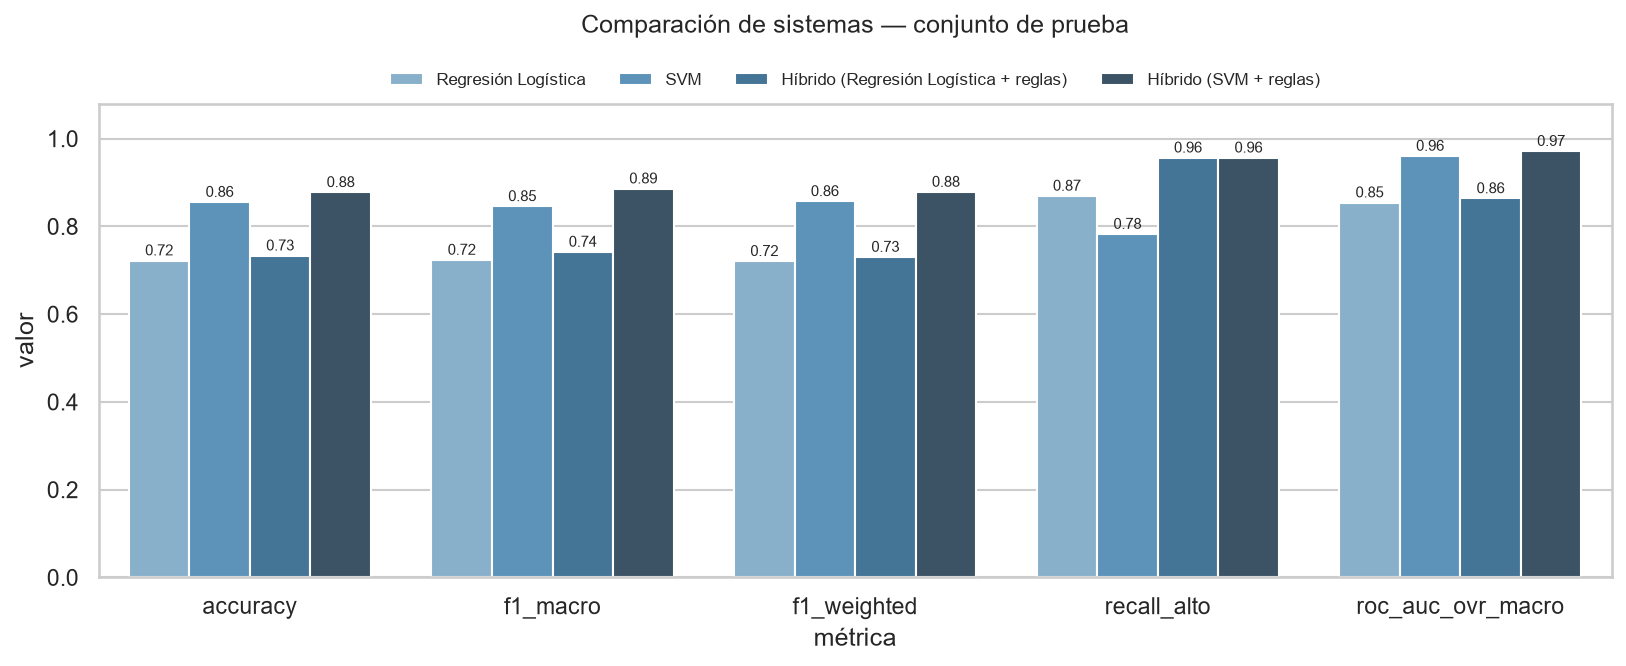

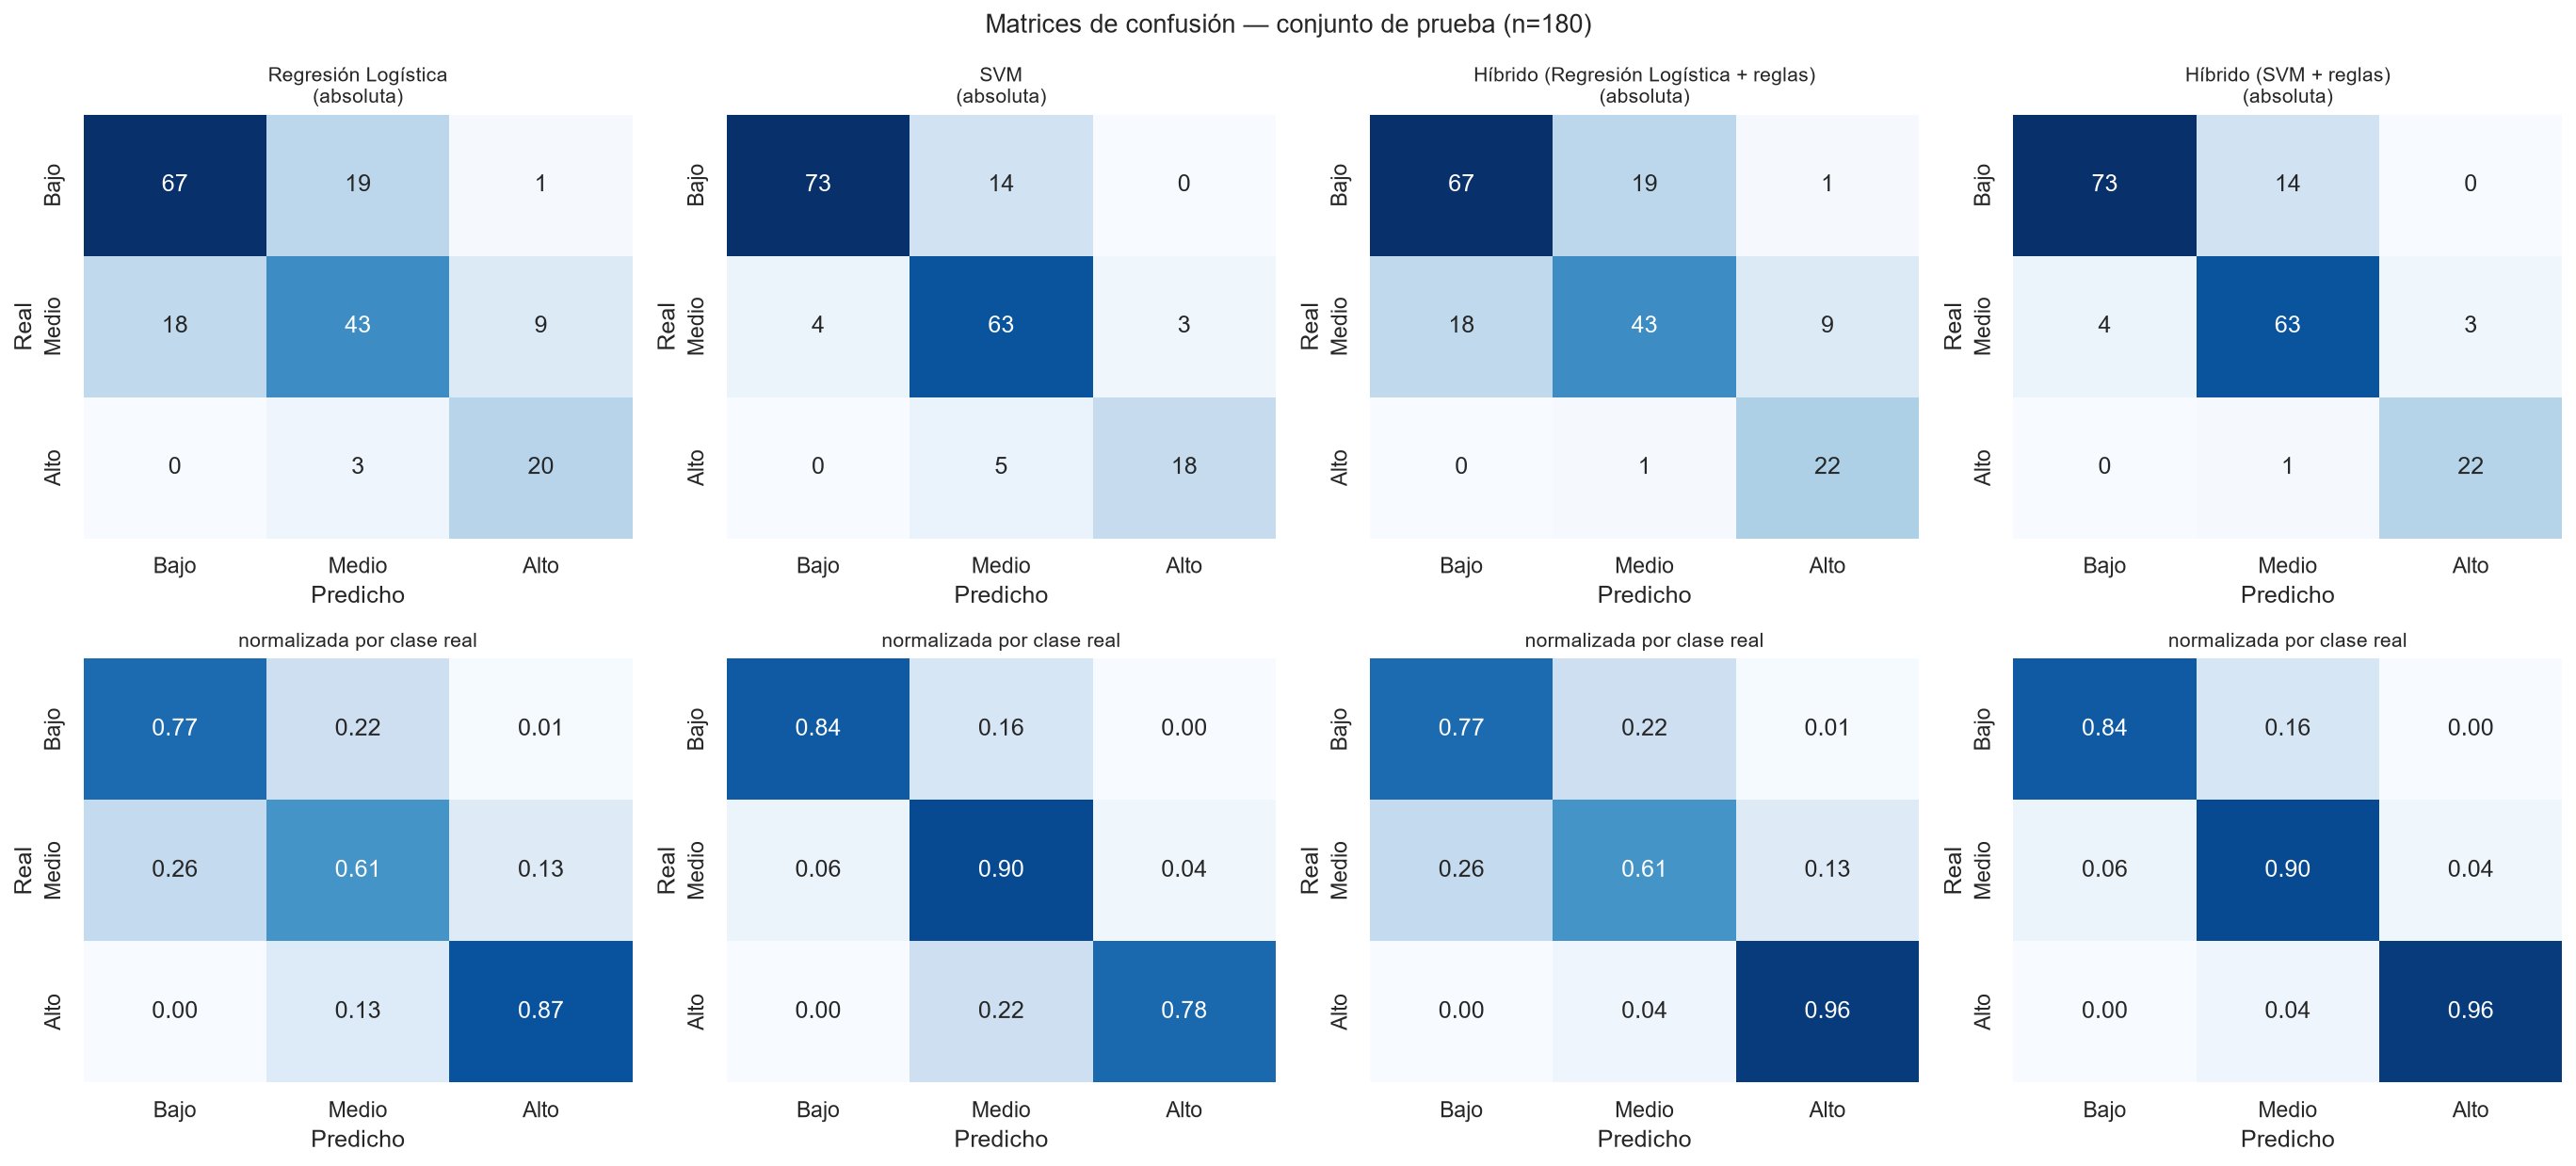

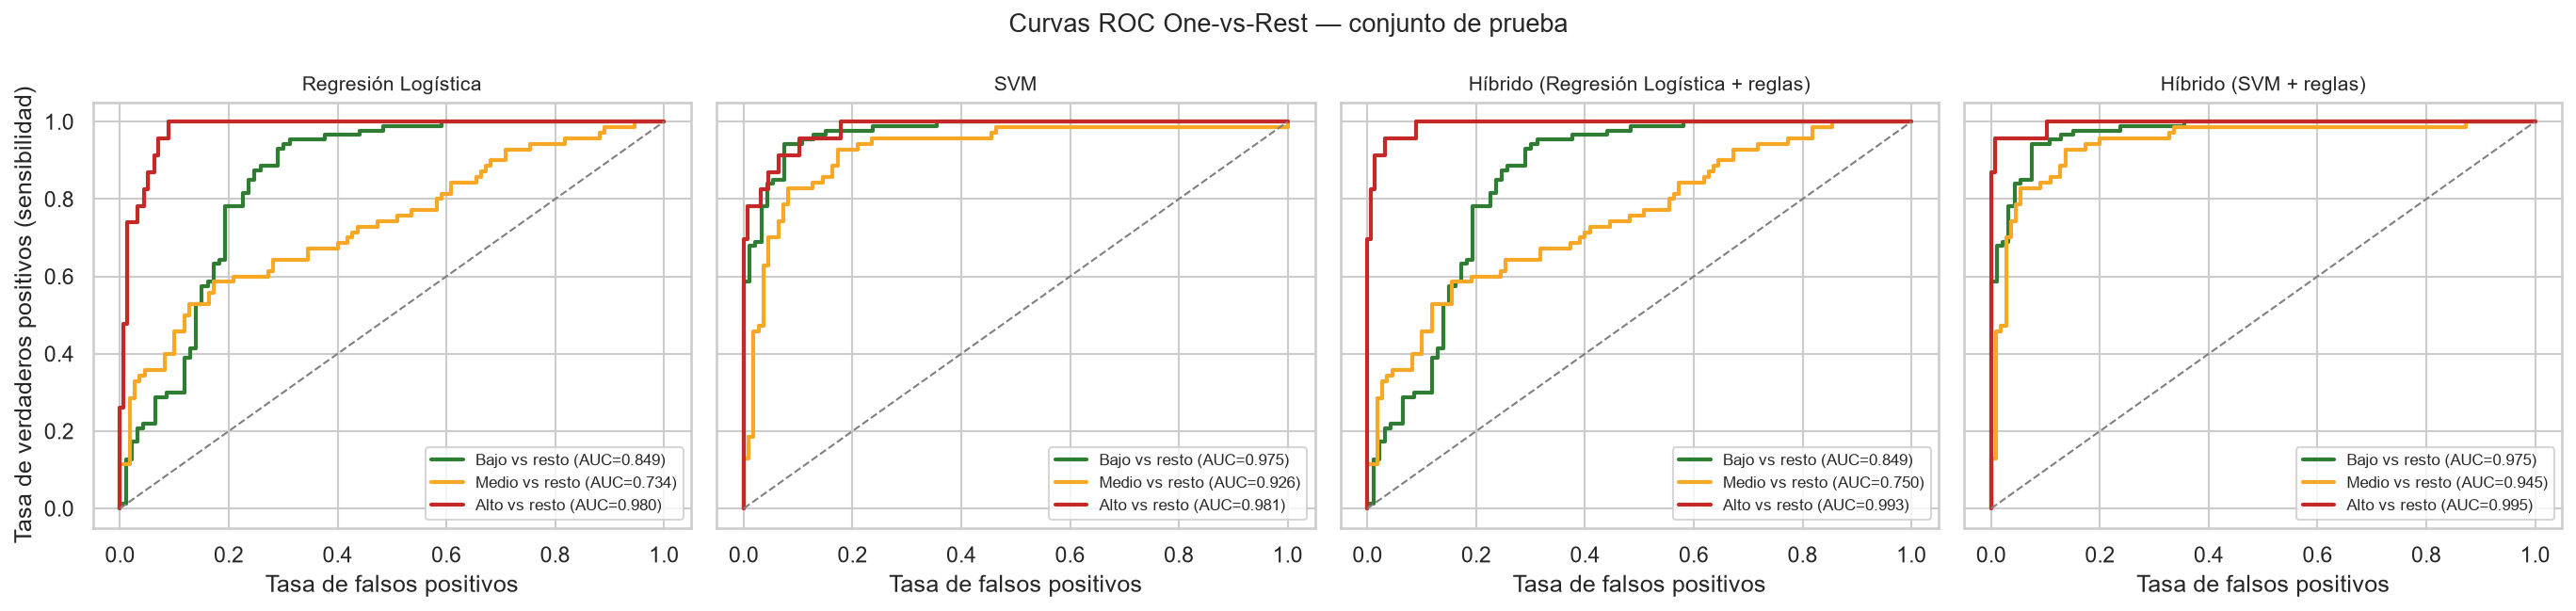

In [12]:
from src.config import DIR_FIGURAS
display(Image(DIR_FIGURAS / "comparacion_sistemas_test.png", width=900))
display(Image(DIR_FIGURAS / "matrices_confusion_test.png", width=1000))
display(Image(DIR_FIGURAS / "curvas_roc_test.png", width=1000))

### Desempeño en el subconjunto sin signos críticos (aporte real del modelo)

In [13]:
tabla_sin_reglas[["n", "accuracy", "f1_macro", "recall_alto", "precision_alto", "falsos_negativos_alto", "costo_clinico_total"]].round(3)

,n,accuracy,f1_macro,recall_alto,precision_alto,falsos_negativos_alto,costo_clinico_total
sistema,,,,,,,
Regresión Logística,166,0.711,0.673,0.889,0.444,1,89
SVM,166,0.867,0.847,0.889,0.727,1,34
Híbrido (Regresión Logística + reglas),166,0.711,0.673,0.889,0.444,1,89
Híbrido (SVM + reglas),166,0.867,0.847,0.889,0.727,1,34


### Costo clínico del error
La matriz de costo ilustrativa (filas = real, columnas = predicho) penaliza más la **subestimación** del riesgo:

| real \ predicho | Bajo | Medio | Alto |
|---|---|---|---|
| **Bajo** | 0 | 1 | 2 |
| **Medio** | 3 | 0 | 1 |
| **Alto** | **10** | **5** | 0 |

Los pesos son un supuesto del equipo y no un estándar oficial. Su propósito es ordenar los sistemas según el daño potencial de sus errores.

### Auditoría de sesgos por subgrupo (predicción fuera de fold sobre los 1.200 registros)

In [14]:
subgrupos.drop(columns="sistema")

,variable,grupo,n,n_alto_real,accuracy,f1_macro,recall_alto
0,area_residencia,Cabecera,499,71,0.882,0.889,0.944
1,area_residencia,Rural disperso,701,81,0.862,0.848,0.778
2,pertenencia_etnica,Afro,120,13,0.875,0.875,0.846
3,pertenencia_etnica,Arhuaco,31,5,0.903,0.922,1.000
4,pertenencia_etnica,Kogui,20,2,0.900,0.925,1.000
5,pertenencia_etnica,Mestiza,370,47,0.884,0.883,0.872
6,pertenencia_etnica,Wayuu,564,70,0.851,0.845,0.814
7,pertenencia_etnica,Wiwa,20,4,0.850,0.839,1.000
8,pertenencia_etnica,Yukpa,75,11,0.920,0.910,0.909
9,departamento,Cesar,431,52,0.905,0.905,0.904


## Conclusiones de la Fase 2
1. **El sistema híbrido SVM + reglas es el mejor** en el conjunto de prueba: F1-macro 0,886 (IC 95 % 0,83–0,93), recall de Alto Riesgo 0,957 (22 de 23), ROC-AUC macro 0,972 y el menor costo clínico (34).
2. **Las reglas compensan la debilidad del SVM.** Por sí solo, el SVM deja escapar 5 de 23 casos de Alto Riesgo. Las reglas recuperan 4, todos con signos críticos. El falso negativo que queda es una gestante sin signos críticos que el modelo clasificó como Riesgo Medio. Ningún caso de Alto Riesgo se clasificó como Bajo.
3. **Rendimiento honesto.** En los 166 casos de prueba sin signos críticos, el SVM obtiene un F1-macro de 0,847 y la Regresión Logística de 0,673. Es la mejor estimación del aporte del aprendizaje automático, y sigue limitada por el origen sintético de las etiquetas.
4. **Sesgo a vigilar.** El recall de Alto Riesgo es más bajo en el área rural dispersa (0,78 frente a 0,94 en cabecera), en La Guajira (0,83 frente a 0,90) y en la atención por parteras o auxiliares (≈0,71–0,73), es decir, justo en la población objetivo. Una causa probable es que en el área rural la ausencia de controles prenatales es 3,6 veces más frecuente (21,8 % frente a 6,0 %), y esos casos son los más difíciles de separar. En la Fase 3 se evaluará ajustar el umbral de decisión por subgrupo o priorizar el recall en el criterio de selección.
5. **Limitación principal.** Los datos son sintéticos y las etiquetas siguen umbrales deterministas. Antes de cualquier uso clínico, se necesita validar el modelo con datos reales anonimizados y con criterio de un especialista.